# Heat redistribution: `insolation_model="naive_redist"`

`naive_redist` keeps the point-source (`naive`) insolation, and so its reflected light, but redistributes the absorbed heat with the toy model of Kreidberg & Loeb (2016, eq. 1):

$$
\sigma T^4(z) =
\begin{cases}
(1-A_B)\,S\left[\dfrac{F}{2} + (1-2F)\cos z\right], & \text{dayside } (z \le 90^\circ)\\[6pt]
(1-A_B)\,S\,\dfrac{F}{2}, & \text{nightside}
\end{cases}
$$

$z$ is the angular distance from the substellar point, $S = \sigma T_\mathrm{eff}^4 (r_2/R)^2$ the substellar insolation, and $F \in [0, 0.5]$ the fraction of the absorbed power the nightside re-radiates: $F = 0$ is the bare rock (identical to `naive`), $F = 0.5$ an isothermal planet. The thermal phase curve is SPIDERMAN's analytic Louden model (`Louden_PhaseCurve`), which evaluates exactly this map.

In [1]:
import numpy as np
import pandas as pd
import contextlib, io
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman
from hyperphase.irradiance import naive_insolation, surface_temperature
from hyperphase.plotting.irradiance import stellar_flux_line
from hyperphase.phasecurve import custom_temperature_grid, full_PhaseCurve, nightside_flux, reflected_PhaseCurve, sigma, thermal_PhaseCurve
from hyperphase.stellar import T_bright
from hyperphase.bands import filter_lambda, filter_loc
from hyperphase.defaults import DEFAULT_A, DEFAULT_A_B, DEFAULT_U, DEFAULT_U_BOL
from hyperphase.parallel import pmap   # process-parallel map: SPIDERMAN holds the GIL, so threads give no speedup
from hyperphase.targets import hi_planets_by_name

In [2]:
planet = hi_planets_by_name("TOI-2431 b")   # an archive planet or a curated entry (inputs/planets/curated_planets.csv)
period = planet.period
u, u_bol = DEFAULT_U, DEFAULT_U_BOL   # transit and irradiance limb darkening
A_B = DEFAULT_A_B                     # Bond albedo: sets the temperature map
A = DEFAULT_A                         # band albedo of the reflected light (full phase curve only)

Instrument = "MIRI/LRS"
lambda_range, filter_path = filter_lambda(Instrument), filter_loc(Instrument)

In [3]:
F_values = np.array([0., 0.01, 0.05, 0.25, 0.5])   # heat redistribution values of Kreidberg & Loeb 2016, Fig. 1

# F is ordered -> one-hue (blue) ramp, light -> dark. The reference models keep a fixed colour throughout the notebook.
F_COLORS = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
C_REDIST, C_HI, C_NAIVE = "#2a78d6", "#eb6834", "#52514e"   # a single naive_redist curve (blue), hyperillum (orange), naive (grey, dashed)
INK, INK_2, AXIS = "#0b0b0b", "#52514e", "#c3c2b7"
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "grid.linestyle": "-",
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "lines.linewidth": 1.5, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "legend.frameon": False, "font.size": 11, "axes.titlesize": 12,
})

F_label = lambda F: f"$F$ = {F:g}"
phase = lambda t: t / period   # orbital phase: 0 = transit, 0.5 = occultation
t = np.linspace(0., period, 1000, endpoint=False)
PHASE_LABEL = "Orbital phase (0 = transit, 0.5 = occultation)"
FLUX_LABEL = "Planet flux $F_p/F_s$ [ppm]"

def F_axis(ax, F_max):
    # linear F axis, restricted to the F range that matters for the plot
    ax.set_xlim(0., F_max)
    ax.set_xlabel("Heat redistribution $F$")

## 1. Temperature profile $T(z)$

`surface_temperature(z, planet, "naive_redist", A_B=..., F=...)` evaluates eq. 1, here for TOI-2431 b and K2-141 b with `hyperillum` and `naive` for reference; shaded: the hyperillumination penumbra. The temperature is continuous at 90° for every $F$; for $0 < F < 0.5$ its slope jumps there.

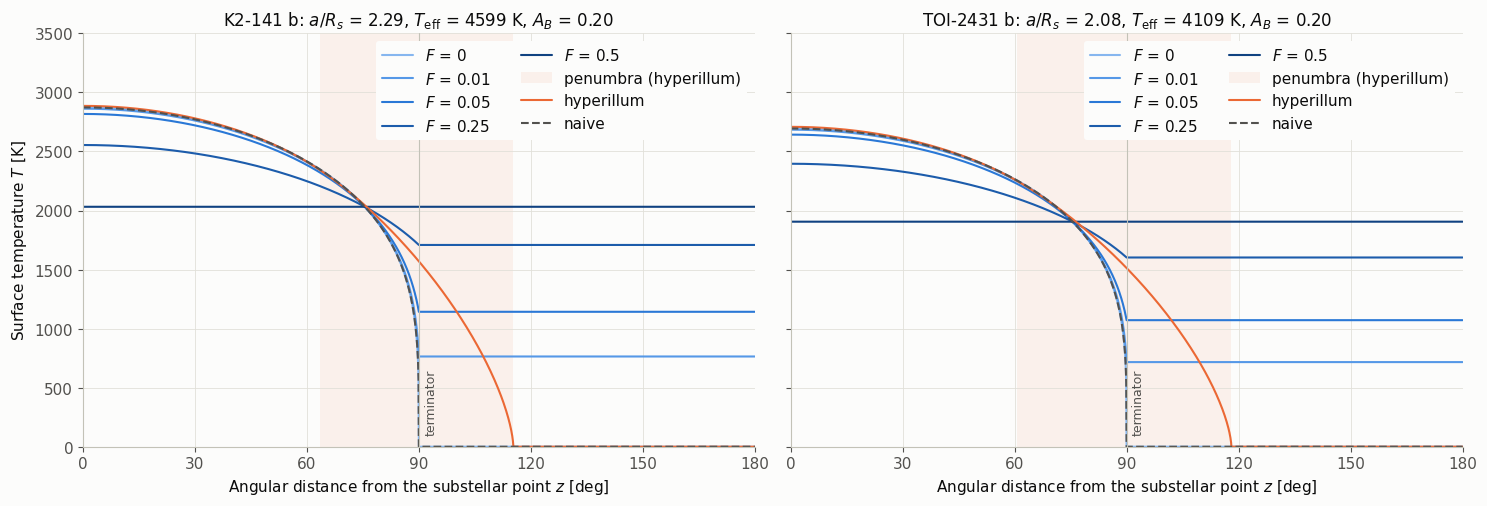

,K2-141 b T_sub [K],K2-141 b T_night [K],TOI-2431 b T_sub [K],TOI-2431 b T_night [K]
F,,,,
0.00,2873.0,0.0,2694.5,0.0
0.01,2862.1,764.0,2684.3,716.5
0.05,2817.5,1142.4,2642.5,1071.4
0.25,2554.5,1708.3,2395.8,1602.2
0.50,2031.5,2031.5,1905.3,1905.3


In [4]:
z = np.linspace(0., np.pi, 2001)   # angular distance from the substellar point (Kreidberg & Loeb's zenith angle)
z_deg = np.degrees(z)
planets = list(hi_planets_by_name(["K2-141 b", "TOI-2431 b"]).values())   # the two reference planets, whatever the target of the setup cell

fig, axs = plt.subplots(1, 2, figsize=(15, 5.2), sharey=True)
for ax, pl in zip(axs, planets):
    for F, col in zip(F_values, F_COLORS):
        ax.plot(z_deg, surface_temperature(z, pl, "naive_redist", A_B=A_B, F=F), color=col, label=F_label(F))
    ax.axvspan(pl.terminator_penumbra(unit="deg"), pl.terminator_nightside(unit="deg"), color=C_HI, alpha=0.08, lw=0, label="penumbra (hyperillum)")
    ax.plot(z_deg, surface_temperature(z, pl, "hyperillum", u_bol=u_bol, A_B=A_B), color=C_HI, label="hyperillum")
    ax.plot(z_deg, surface_temperature(z, pl, "naive", A_B=A_B), color=C_NAIVE, ls="--", label="naive")
    ax.axvline(90., color=AXIS, lw=0.8)
    ax.text(91.5, 100., "terminator", rotation=90, color=INK_2, fontsize=9, va="bottom")
    ax.set(xlabel="Angular distance from the substellar point $z$ [deg]", xlim=(0, 180), ylim=(0, 3500),
           title=f"{pl.name}: $a/R_s$ = {pl.R / pl.r2:.2f}, $T_\\mathrm{{eff}}$ = {pl.T2_eff:.0f} K, $A_B$ = {A_B:.2f}")
    ax.set_xticks(np.arange(0, 181, 30))
    ax.legend(loc="upper right", ncol=2, frameon=True, facecolor="#fcfcfb", edgecolor="none", framealpha=1.)
axs[0].set_ylabel("Surface temperature $T$ [K]")
plt.tight_layout()
plt.show()

rows = [{"F": F, **{f"{pl.name} {name} [K]": float(surface_temperature(z_, pl, "naive_redist", A_B=A_B, F=F))
                    for pl in planets for name, z_ in (("T_sub", 0.), ("T_night", np.pi))}} for F in F_values]
pd.DataFrame(rows).set_index("F").round(1)

**Energy budget.** Integrating $\sigma T^4$ over the sphere must return the absorbed power $(1-A_B)\,S\,\pi r_1^2$ for every $F$, and the nightside must emit the fraction $F$ of it.

In [5]:
n_lo_e, n_la_e = 2000, 1000
lo_e = (np.arange(n_lo_e) + 0.5) / n_lo_e * 2 * np.pi - np.pi   # cell centres [rad]
la_e = (np.arange(n_la_e) + 0.5) / n_la_e * np.pi - np.pi / 2
LO_e, LA_e = np.meshgrid(lo_e, la_e)
dA = np.cos(LA_e) * (2 * np.pi / n_lo_e) * (np.pi / n_la_e)     # area element per unit r1^2
z_e = np.arccos(np.clip(np.cos(LA_e) * np.cos(LO_e), -1., 1.))
nightside = np.abs(LO_e) > np.pi / 2

S = float(naive_insolation(0., planet))   # substellar insolation [W/m^2]
absorbed = (1 - A_B) * S * np.pi           # per unit r1^2

rows = []
for F in F_values:
    emitted = sigma * surface_temperature(z_e, planet, "naive_redist", A_B=A_B, F=F)**4 * dA
    rows.append({"F": F, "emitted / absorbed": emitted.sum() / absorbed, "nightside share of the emission": emitted[nightside].sum() / emitted.sum()})
pd.DataFrame(rows).set_index("F").round(5)

,emitted / absorbed,nightside share of the emission
F,,
0.00,1.0,0.00
0.01,1.0,0.01
0.05,1.0,0.05
0.25,1.0,0.25
0.50,1.0,0.50


## 2. Temperature maps

`custom_temperature_grid(..., insolation_model="naive_redist", F=F)` on the (longitude, latitude) grid, with `hyperillum` in the last panel; one colour scale, white lines at the terminator.

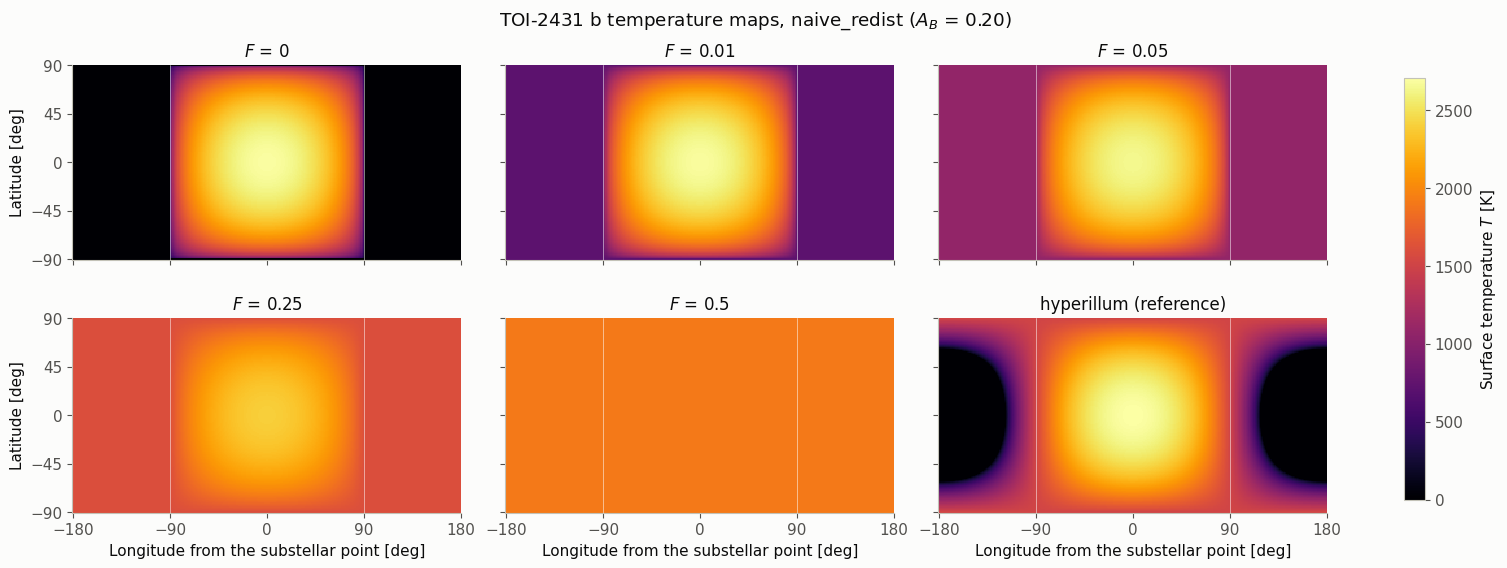

In [6]:
maps = {F: custom_temperature_grid(planet, insolation_model="naive_redist", F=F, A_B=A_B)[2] for F in F_values}
lo, la, T_hi = custom_temperature_grid(planet, insolation_model="hyperillum", u_bol=u_bol, A_B=A_B)
T_max = max([T_hi.max()] + [Tg.max() for Tg in maps.values()])

fig, axs = plt.subplots(2, 3, figsize=(15, 5.6), sharex=True, sharey=True, constrained_layout=True)
panels = [(F_label(F), maps[F]) for F in F_values] + [("hyperillum (reference)", T_hi)]
for ax, (title, Tg) in zip(axs.ravel(), panels):
    im = ax.pcolormesh(lo, la, Tg, cmap="inferno", vmin=0., vmax=T_max, shading="auto", rasterized=True)
    for x in (-90., 90.):
        ax.axvline(x, color="w", lw=0.6, alpha=0.6)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xticks(np.arange(-180, 181, 90)); ax.set_yticks(np.arange(-90, 91, 45))
for ax in axs[-1]: ax.set_xlabel("Longitude from the substellar point [deg]")
for ax in axs[:, 0]: ax.set_ylabel("Latitude [deg]")
fig.colorbar(im, ax=axs, label="Surface temperature $T$ [K]", shrink=0.85)
fig.suptitle(f"{planet.name} temperature maps, naive_redist ($A_B$ = {A_B:.2f})")
plt.show()

## 3. Thermal phase curves for a range of $F$

`thermal_PhaseCurve(..., insolation_model="naive_redist", F=F)` dispatches to `Louden_PhaseCurve`. The curves are the planet's thermal light curve without the transit: redistribution lowers the dayside, raises the nightside and flattens the curve at $F = 0.5$. The nightside columns of the table come from `nightside_flux` at transit.

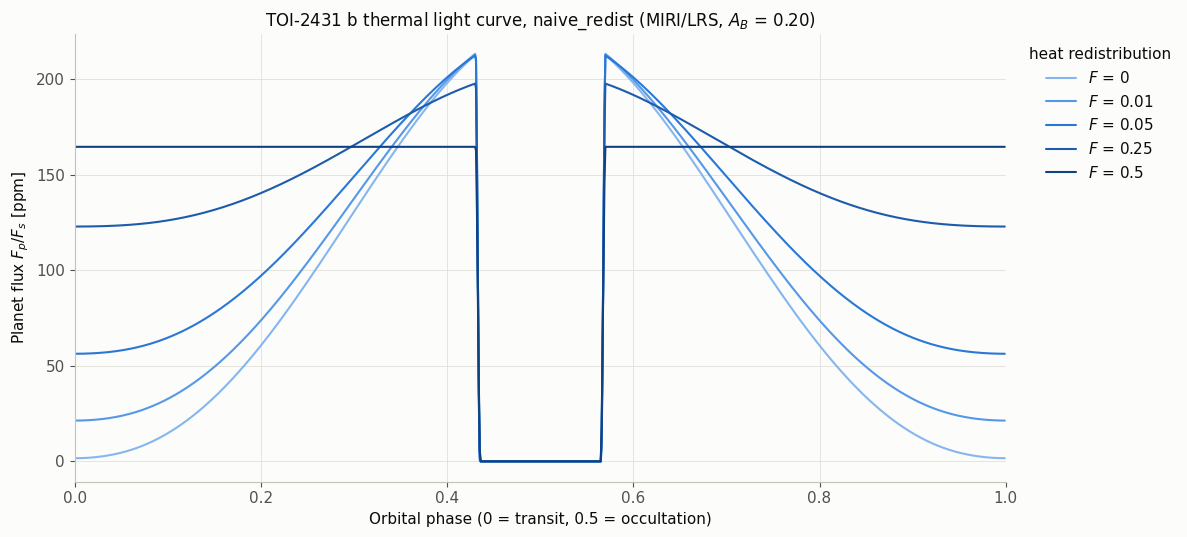

,T_night (eq. 1) [K],occultation depth [ppm],dayside T_bright [K],nightside flux [ppm],nightside T_bright [K],peak-to-trough [ppm]
model,,,,,,
"naive_redist, F = 0",0.0,228.2,2347.5,1.6,369.7,226.6
"naive_redist, F = 0.01",716.5,227.7,2344.0,21.3,732.7,206.4
"naive_redist, F = 0.05",1071.4,224.7,2323.3,56.3,1079.0,168.4
"naive_redist, F = 0.25",1602.2,204.0,2181.1,122.8,1603.9,81.2
"naive_redist, F = 0.5",1905.3,164.6,1905.1,164.6,1905.1,0.0
hyperillum,NaN,232.3,2375.6,10.2,578.0,222.1
naive,NaN,228.2,2347.4,1.6,369.7,226.5


In [7]:
kw = dict(u_bol=u_bol, filter_path=filter_path, A_B=A_B)

def thermal_curves(model, F):
    # thermal light curve (with occultation) and pure phase variation (without) [ppm], the occultation depth [ppm], and the nightside at transit from nightside_flux: thermal flux [ppm] and brightness temperature [K]
    _, lc, fp_, _ = thermal_PhaseCurve(planet, lambda_range, t=t, u=u, insolation_model=model, F=F, include_transit=False, **kw)
    _, pv, _, _ = thermal_PhaseCurve(planet, lambda_range, t=t, u=u, insolation_model=model, F=F, include_transit=False, include_occultation=False, **kw)
    night = nightside_flux(planet, lambda_range, model, unit="flux", F=F, **kw)[0]
    T_night = nightside_flux(planet, lambda_range, model, unit="temperature", F=F, **kw)
    return lc * 1e6, pv * 1e6, fp_, night, T_night

runs = [("naive_redist", F) for F in F_values] + [("hyperillum", None), ("naive", None)]
out = pmap(thermal_curves, runs)
redist = {F: o for (m, F), o in zip(runs, out) if m == "naive_redist"}   # F -> (light curve, phase variation, depth, nightside flux, nightside T_bright)
ref = {m: o for (m, F), o in zip(runs, out) if m != "naive_redist"}      # reference models

fig, ax = plt.subplots(figsize=(12, 5.5))
for F, col in zip(F_values, F_COLORS):
    ax.plot(phase(t), redist[F][0], color=col, label=F_label(F))
ax.set(xlabel=PHASE_LABEL, ylabel=FLUX_LABEL, xlim=(0, 1), title=f"{planet.name} thermal light curve, naive_redist ({Instrument}, $A_B$ = {A_B:.2f})")
ax.legend(title="heat redistribution", loc="upper left", bbox_to_anchor=(1.01, 1.))
plt.tight_layout()
plt.show()

def observables(lc, pv, fp_, night, T_night):
    return {"occultation depth [ppm]": fp_,
            "dayside T_bright [K]": T_bright(fp_, planet, lambda_range, filter_path=filter_path),
            "nightside flux [ppm]": night,          # at transit, the nightside faces the observer (nightside_flux)
            "nightside T_bright [K]": T_night,      # brightness temperature of that flux; for naive_redist it reproduces T_night (eq. 1) up to the dayside sliver seen past the pole (i < 90 deg)
            "peak-to-trough [ppm]": np.ptp(pv)}

rows = [{"model": f"naive_redist, F = {F:g}", "T_night (eq. 1) [K]": float(surface_temperature(np.pi, planet, "naive_redist", A_B=A_B, F=F)), **observables(*redist[F])} for F in F_values]
rows += [{"model": m, **observables(*ref[m])} for m in ("hyperillum", "naive")]
pd.DataFrame(rows).set_index("model").round(1)

The full phase curve (`full_PhaseCurve`) adds the transit and the reflected light, which is that of `naive` and does not depend on $F$.

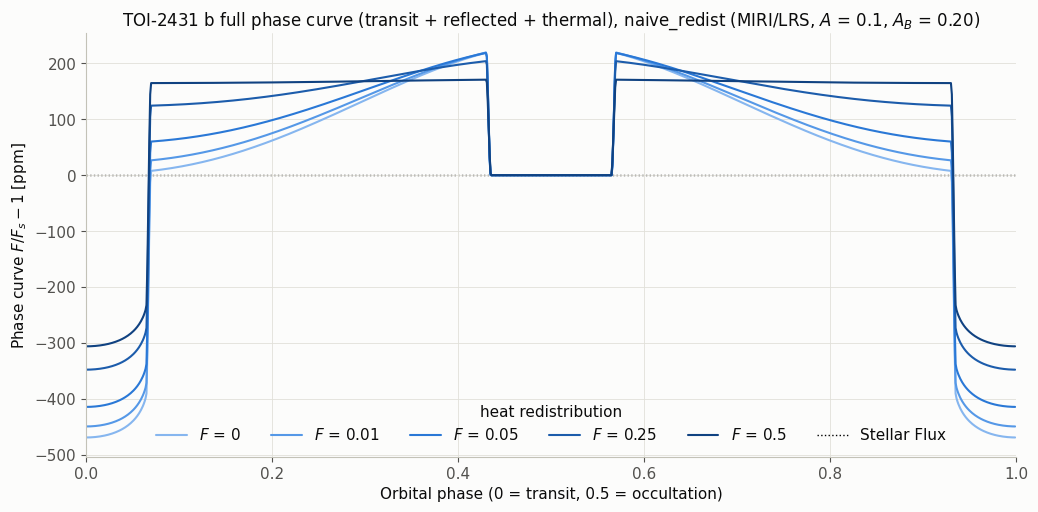

,full occultation depth [ppm],thermal occultation depth [ppm]
F,,
0.00,234.94,228.19
0.01,234.43,227.69
0.05,231.41,224.67
0.25,210.75,204.01
0.50,171.29,164.55


In [8]:
def full_curve(F):
    _, fc, fp_ = full_PhaseCurve(planet, lambda_range, t=t, u=u, u_bol=u_bol, A=A, A_B=A_B, filter_path=filter_path, insolation_model="naive_redist", F=F)
    return (fc - 1.) * 1e6, fp_

full = dict(zip(F_values, pmap(full_curve, [(F,) for F in F_values])))

fig, ax = plt.subplots(figsize=(12, 5.5))
for F, col in zip(F_values, F_COLORS):
    ax.plot(phase(t), full[F][0], color=col, label=F_label(F))
stellar_flux_line(ax)
ax.set(xlabel=PHASE_LABEL, ylabel="Phase curve $F/F_s - 1$ [ppm]", xlim=(0, 1),
       title=f"{planet.name} full phase curve (transit + reflected + thermal), naive_redist ({Instrument}, $A$ = {A:g}, $A_B$ = {A_B:.2f})")
ax.legend(title="heat redistribution", loc="lower center", ncol=6)
plt.show()

pd.DataFrame({"F": F_values, "full occultation depth [ppm]": [full[F][1] for F in F_values],
              "thermal occultation depth [ppm]": [redist[F][2] for F in F_values]}).set_index("F").round(2)

## 4. Consistency check: `naive_redist` with $F = 0$ vs `naive`

With $F = 0$, eq. 1 is the `naive` map and the reflected light is identical. The thermal curves still differ slightly because they take different SPIDERMAN paths: `naive` interpolates a `direct_T` grid (bicubic), `naive_redist` evaluates the map analytically (Louden); both with the point-source default of `N_LAYERS`.

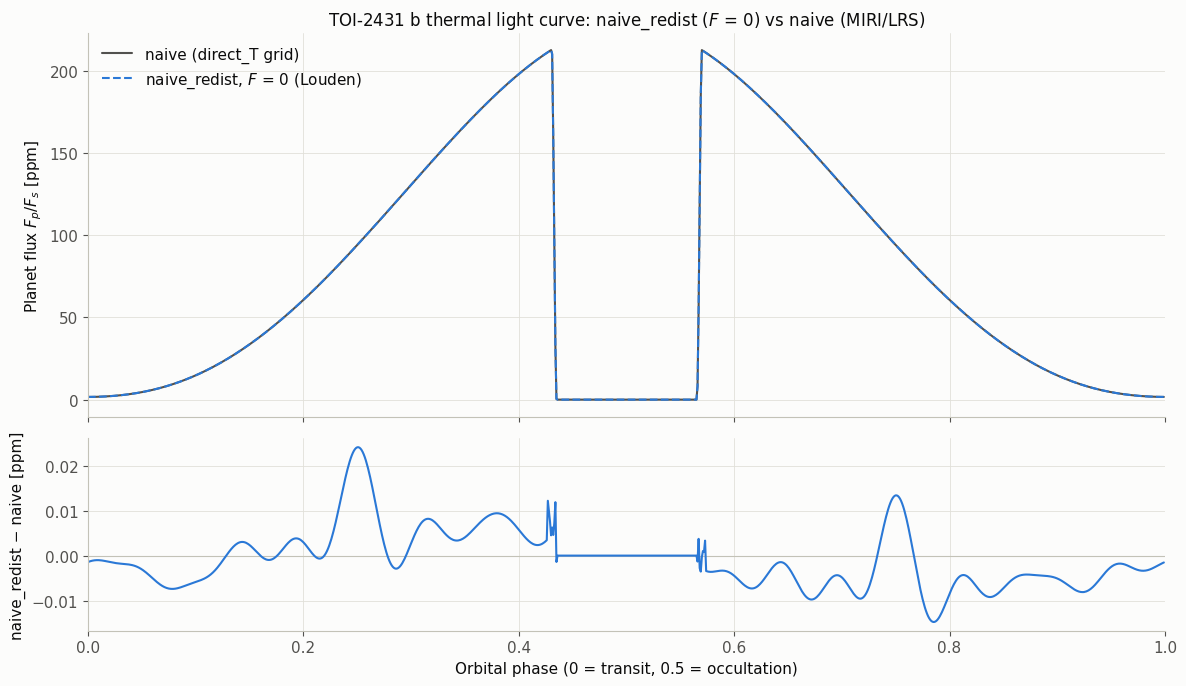

temperature maps identical:     True
reflected phase curves identical: True
thermal light curves: max |diff| = 0.0241 ppm, rms = 0.0065 ppm
occultation depth: naive_redist (F=0) 228.195 ppm, naive 228.187 ppm


In [9]:
lc_n, lc_0 = ref["naive"][0], redist[0.][0]

fig, (ax, axr) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
ax.plot(phase(t), lc_n, color=C_NAIVE, label="naive (direct_T grid)")
ax.plot(phase(t), lc_0, color=C_REDIST, ls="--", label="naive_redist, $F$ = 0 (Louden)")
ax.set(ylabel=FLUX_LABEL, title=f"{planet.name} thermal light curve: naive_redist ($F$ = 0) vs naive ({Instrument})")
ax.legend(loc="upper left")
axr.axhline(0., color=AXIS, lw=0.8)
axr.plot(phase(t), lc_0 - lc_n, color=C_REDIST)
axr.set(xlabel=PHASE_LABEL, ylabel="naive_redist − naive [ppm]", xlim=(0, 1))
plt.tight_layout()
plt.show()

_, refl_n, _ = reflected_PhaseCurve(planet, t=t, u=u, A=A, insolation_model="naive")
_, refl_r, _ = reflected_PhaseCurve(planet, t=t, u=u, A=A, insolation_model="naive_redist")
print(f"temperature maps identical:     {np.array_equal(maps[0.], custom_temperature_grid(planet, insolation_model='naive', A_B=A_B)[2])}")
print(f"reflected phase curves identical: {np.array_equal(refl_n, refl_r)}")
print(f"thermal light curves: max |diff| = {np.abs(lc_0 - lc_n).max():.4f} ppm, rms = {np.sqrt(np.mean((lc_0 - lc_n)**2)):.4f} ppm")
print(f"occultation depth: naive_redist (F=0) {redist[0.][2]:.3f} ppm, naive {ref['naive'][2]:.3f} ppm")

## 5. Observables as a function of $F$

Occultation depth, peak-to-trough amplitude and nightside flux at transit on a fine grid up to $F = 0.1$, where the observables change fastest with $F$; dots: the $F$ values of section 3, lines: `hyperillum` and `naive`.

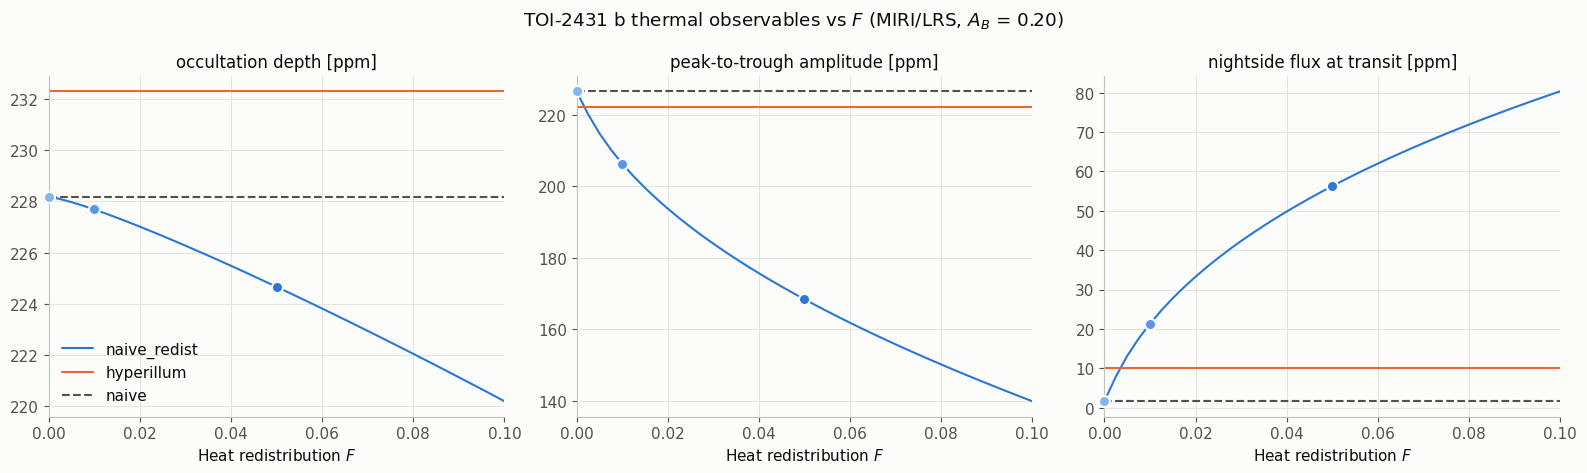

In [10]:
F_MAX_OBS = 0.1   # plotted F range
F_grid = np.linspace(0., F_MAX_OBS, 41)
obs = pmap(thermal_curves, [("naive_redist", F) for F in F_grid])
series = {"occultation depth [ppm]": lambda o: o[2],
          "peak-to-trough amplitude [ppm]": lambda o: np.ptp(o[1]),
          "nightside flux at transit [ppm]": lambda o: o[3]}

fig, axs = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (name, get) in zip(axs, series.items()):
    ax.plot(F_grid, [get(o) for o in obs], color=C_REDIST, label="naive_redist")
    for F, col in zip(F_values, F_COLORS):
        if F <= F_MAX_OBS:
            ax.plot(F, get(redist[F]), "o", ms=8, color=col, mec="#fcfcfb", mew=1.5, zorder=4, clip_on=False)
    ax.axhline(get(ref["hyperillum"]), color=C_HI, label="hyperillum")
    ax.axhline(get(ref["naive"]), color=C_NAIVE, ls="--", label="naive")
    ax.set_title(name)
    F_axis(ax, F_MAX_OBS)
axs[0].legend(loc="lower left")
fig.suptitle(f"{planet.name} thermal observables vs $F$ ({Instrument}, $A_B$ = {A_B:.2f})")
plt.tight_layout()
plt.show()